# 21. Новый ракурс, цена кадра и следы ошибок

[План курса](../../README_ru.md)

Две модели могут одинаково хорошо выглядеть спереди. При небольшом повороте у одной край остаётся на месте, у другой в воздухе проступает тёмное пятно. Один удачно выбранный кадр этого не покажет. Статическую сцену удобно осматривать сразу тремя способами: глазами, картой различий и измерением на ракурсе, пиксели которого не участвовали в обучении.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'

import photo_diagnostics as inspect_photo

## Куда пропала деталь

В опыте три вида цветной сцены дают градиенты, ещё два удержаны. Рядом стоят эталон, рендер и яркость ошибки. Ползунок усиливает одно известное изменение: расширение пятен, лишний непрозрачный объект перед сценой или потерю зелёного. Причина в каждом случае задана намеренно. У настоящей реконструкции похожий след лишь подскажет, что проверять следующим.


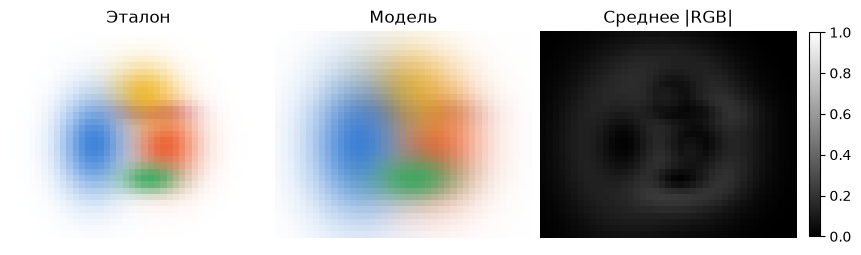

In [2]:
frames, seed = synthetic_capture()
clean, history = fit_colors(seed,frames,steps=12)
def probe(i, kind, strength):
    return error_figure(frames,clean,int(i),kind,strength,lang)
display(probe(1,"blur",.45)); plt.close()
controls(probe,i=list(range(5)),kind=["blur","floater","tint"],strength=(0,1,.05,.45))


## Сначала честная пара изображений

«Тестовый» здесь означает, что RGB кадра исключён из подбора параметров. Положение камеры при проверке известно. По трём обучающим ракурсам мы можем измерить, как хорошо модель запомнила данные. По двум другим видно, насколько хорошо она переносит форму в новые виды. Соседние кадры из одной почти неподвижной видеосерии слабо проверяют широкую смену ракурса. Фотографии для выбора размера шага или числа итераций образуют отдельную валидационную выборку. Если подбирать параметры по тестовой картинке снова и снова, её роль меняется.

Сравним одинаковые пиксели при одной камере, разрешении, области изображения и фоне. Пусть четыре нормированных красных значения образца равны $[0.2,0.4,0.6,0.8]$, а предсказание $[0.3,0.4,0.4,0.9]$. Вычитаем образец из предсказания в соответствующем месте. Получаются $[0.1,0,-0.2,0.1]$. Сумма ноль, хотя три значения ошибочны. Модули складываются в $0.4$. Средняя абсолютная ошибка MAE равна $0.4/4=0.1$. Квадраты дают $0.01+0+0.04+0.01=0.06$. Средняя квадратичная ошибка MSE равна $0.06/4=0.015$.

В цветном кадре каждый канал даёт отдельное сравнение. На 40 × 30 пикселях получается $40\cdot30\cdot3=3600$ чисел. На карте справа один пиксель показывает среднее трёх **модулей**. Если отклонён только красный на 0.3, на карте будет $0.3/3=0.1$. Изменение экспозиции, цветового пространства, маски фона или границ обрезки способно изменить метрику при той же геометрии. В этих примерах сравниваются декодированные RGB в [0,1] без преобразования в линейный свет.


In [3]:
reference = np.array([.2,.4,.6,.8])
predicted = np.array([.3,.4,.4,.9])
print("residual:", (predicted-reference).round(3))
print(scores(predicted,reference))
assert np.isclose(scores(predicted,reference)["mse"], .015)


residual: [ 0.1  0.  -0.2  0.1]
{'mae': 0.09999999999999998, 'mse': 0.014999999999999993, 'psnr': 18.23908740944319}


## Одинаковая оценка, разные картинки

Два серых квадрата размером 16 × 16 имеют яркость 0,5 во всех трёх каналах. В первой копии добавим 0,05 везде. Во второй добавим 0,2 только внутри квадратика 4 × 4. На картинке это разные дефекты: весь кадр слегка выцвел или на серой поверхности появилось светлое пятно.

В первом случае на каждый из 256 пикселей приходится квадрат ошибки $0{,}05^2=0{,}0025$. Во втором ошиблись всего $4\cdot4=16$ пикселей из 256. Каждый дал $0{,}2^2=0{,}04$, и среднее по кадру оказалось $(16/256)\cdot0{,}04=0{,}0025$. Каналы одинаковы, поэтому среднее по RGB ничего не меняет. А средняя **абсолютная** ошибка разная — 0,05 против $(16/256)\cdot0{,}2=0{,}0125$. Квадрат сильнее выделил редкое большое отклонение. Ещё одна потеря информации неизбежна при любом из этих средних: если перенести пятно в угол, числа останутся прежними. Узнать, испорчен ли силуэт или пустой фон, можно по самой карте.

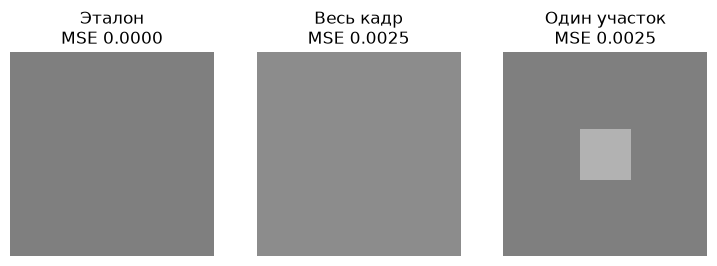

In [4]:
gray = np.full((16,16,3),.5)
shift = gray+.05
patch = gray.copy(); patch[6:10,6:10] += .2
fig,axes=plt.subplots(1,3,figsize=(7.4,2.55),layout="constrained")
labels = ["Эталон","Весь кадр","Один участок"] if lang=="ru" else ["Reference","Whole frame","One patch"]
for ax,im,title in zip(axes,[gray,shift,patch],labels):
    metric=scores(im,gray)
    ax.imshow(im,interpolation="nearest")
    ax.set_title(f"{title}\nMSE {metric['mse']:.4f}"); ax.axis("off")
plt.show()
assert np.isclose(scores(gray,shift)["mse"],scores(gray,patch)["mse"])

## Зачем шкала в децибелах

PSNR берёт ту же MSE, но переворачивает направление шкалы. Пусть $A$ — максимальное значение канала в **данном представлении**, например 1. Тогда

$$
\mathrm{PSNR}=10\log_{10}\!\left(\frac{A^2}{\mathrm{MSE}}\right).
$$

Сначала возводим максимум в квадрат, чтобы сравнивались величины в одних единицах. Затем делим его на ошибку. В опыте выше $1/0.015\approx66.67$. Десятичный логарифм спрашивает, в какую степень возвести 10, чтобы получить 66.67. Это примерно 1.824. Умножение на 10 даёт 18.24 дБ. Вдвое меньшая MSE добавляет $10\log_{10}2\approx3.01$ дБ. При точном совпадении ошибка нулевая, а PSNR принято считать бесконечной. Для байтов с максимумом 255 меняется и $A$, и сама MSE. Нельзя подставлять 255 сверху, оставив нормированную ошибку снизу.

Среднее по логарифмам отдельных кадров отличается от логарифма средней ошибки. Например, для двух равных кадров с MSE 0.01 и 0.09 PSNR составляет 20 и примерно 10.46 дБ. Их среднее около 15.23 дБ. Объединённая MSE равна 0.05 и даёт около 13.01 дБ. Таблица ниже сохраняет отдельную строку на камеру, чтобы один сложный вид не исчезал в среднем.


In [5]:
for split in ("train","test"):
    for row in evaluate(clean,frames,split):
        print(split, row["name"], "MSE", round(row["mse"],7), "PSNR", round(row["psnr"],2))


train view_-32.png MSE 8.6e-06 PSNR 50.67
train view_+00.png MSE 1.52e-05 PSNR 48.19
train view_+35.png MSE 4.19e-05 PSNR 43.78
test view_-15.png MSE 9.1e-06 PSNR 50.43
test view_+21.png MSE 3.03e-05 PSNR 45.19


## Другая камера той же скульптуры

Теперь возьмём настоящую фотографию view-04. Её не было среди восьми обучающих кадров. У более подробного примера 117 пятен. Они начинались с разреженных точек и уточнялись в течение 1200 шагов по случайным обучающим пикселям. Для оценки используется всё изображение 80 × 60. Важно сравнить обе картинки одного размера. Эта версия лучше собирает крупный силуэт, но границы формы и мелкая фактура всё ещё размыты. Если фотографировать только с одной стороны, обратная поверхность и в большой модели остаётся догадкой. [Фотографии NVIDIA Corporation, PhysicalAI-NuRec-PPISP, CC BY 4.0](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example) · [Воспроизводимое обучение](https://github.com/HeinrichWirth/gaussian-splatting-course/blob/main/scripts/train_photo_reference.py)


view-04.jpg {'mae': 0.07100254932146274, 'mse': 0.009817480629714553, 'psnr': 20.079999469372364}


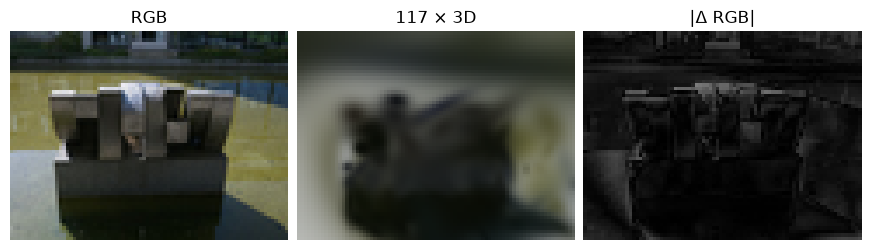

In [6]:
from reconstruction_demos import ROOT
photos, _ = photo_capture(max_side=80)
reference_path = ROOT / "site/dist/assets/reconstruction/photo-reference.json"
photo_model = json.loads(reference_path.read_text(encoding="utf8"))
image = next(f for f in photos if f["split"]=="test")
h,w = image["rgb"].shape[:2]
result = render_scene(photo_model,image["camera"],w,h)
print(image["name"], scores(result,image["rgb"]))
fig, ax = plt.subplots(1,3,figsize=(8.6,3),layout="constrained")
for a,title,im in zip(ax, ["RGB", "117 × 3D","|Δ RGB|"], [image["rgb"],result,np.abs(result-image["rgb"]).mean(axis=2)]):
    a.imshow(im,cmap="gray",vmin=0,vmax=1);a.set_title(title);a.axis("off")
plt.show()


## Сколько ошибки приходится на сам предмет

Фотография имеет 80 × 60 пикселей. Рамка размером 40 × 30 занимает 1200 из 4800 пикселей, то есть четверть снимка. Сначала она лежит в центре, от столбца 20 до 59 и от строки 15 до 44 включительно. Это обычный прямоугольник, в него попадают и камень, и часть фона. Если в съёмке есть проверенная маска предмета, те же вычисления работают с маской любой формы.

Цвет на карте показывает среднеквадратичное отклонение **в отдельном пикселе**. Из трёх остатков берутся квадраты, их среднее, затем корень. Например, $(0{,}3;\,0;\,0)$ даст $\sqrt{(0{,}09+0+0)/3}\approx0{,}173$. Ноль тёмный, единица соответствует верхней границе шкалы. Яркий след показывает место; по нему ещё нельзя определить, какой канал завышен.

У центральной области MSE примерно 0,011932, у остального кадра — 0,009113. Среднее по всем пикселям равно $0{,}25\cdot0{,}011932+0{,}75\cdot0{,}009113\approx0{,}009817$. Здесь 0,25 и 0,75 — доли площади. Чтобы узнать, сколько **суммарной** ошибки попало внутрь, нужно поделить вклад первой части на весь результат. Получается $0{,}25\cdot0{,}011932/0{,}009817\approx0{,}304$, или около 30,4%. Рамка занимает четверть кадра и собирает чуть меньше трети ошибки. При движении рамки полная MSE остаётся прежней. Меняется ответ на вопрос, где именно потеряно качество.

<details><summary>Можно ли объявить победителя по одному аккуратно выбранному прямоугольнику?</summary>

Если прямоугольник появился после просмотра результатов, по нему легко подобрать выгодный участок для любой модели. Для сравнения двух вариантов годится одна и та же заранее определённая маска, одна пара камер и общая шкала карт. Полный кадр рядом с маской оставляет видимой цену улучшения — например, выигрыш на камне может сопровождаться новым пятном на фоне.

</details>

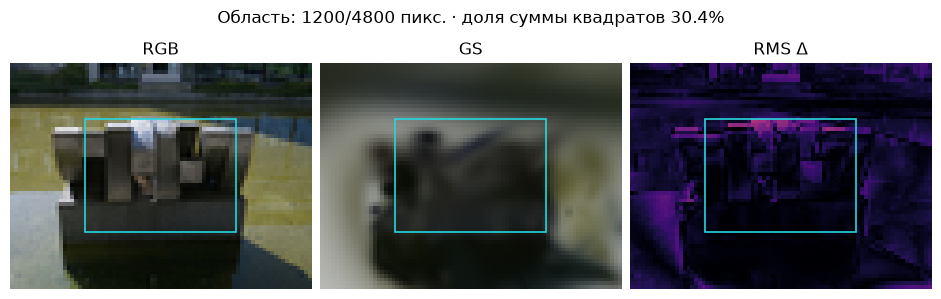

In [7]:
def inspect_region(left,top):
    return inspect_photo.region_figure(image["rgb"],result,int(left),int(top),lang=lang)
display(inspect_region(20,15)); plt.close()
controls(inspect_region,left=(0,40,1,20),top=(0,30,1,15))

## Как читать разные следы

**Плавающий фрагмент.** Один вид может скрыть ошибочную глубину. При небольшом движении камеры тёмное пятно слезает с поверхности и закрывает фон. Полезный опыт — оставить геометрию и пройти короткую дугу. Если сдвиг пятна относительно фона слишком велик, подозрение падает на его глубину; проверка известных поз и треков помогает отделить ошибку камеры.

**Размытие.** У раздутых гауссиан остаток идёт вдоль контура. Такой же след дают смазанный обучающий кадр, грубая сетка или несколько несогласованных положений камеры. Сравнение резких исходников и проекций точек помогает разделить причины. Добавление пятен на неверно совмещённые кадры может лишь запомнить ошибку.

**Мерцание.** Два близких угла дают резкий скачок цвета. Переключение порядка близких по глубине полупрозрачных пятен, завышенная зависимость цвета от направления или недостаточная фильтрация мелких следов могут дать похожий эффект. Последовательность соседних камер при неизменной сцене проверяет скачок. Метрика одного кадра об этом почти ничего не говорит.

**Оттенок.** При ослабленном зелёном канале ошибка окрашивает всю знакомую поверхность. Если сдвиг примерно одинаков во всех видах, помогает проверка экспозиции и обработки RGB. Если промах меняет знак с углом, полезно отдельно рассмотреть направленную составляющую цвета.

У авторов также измеряются **SSIM** и **LPIPS**. SSIM сравнивает яркость и совместный рисунок локальных окон. Два серых окна $[0.2,0.8]$ и $[0.3,0.7]$ имеют среднюю яркость 0.5. Отклонения от неё равны $[-0.3,0.3]$ и $[-0.2,0.2]$. Средние квадраты отклонений — 0.09 и 0.04, среднее произведение — 0.06. В таком окне вклад яркости равен 1, а контраст и совместный рисунок дают $(2\cdot0.06+0.0009)/(0.09+0.04+0.0009)\approx0.924$. Малая константа удерживает знаменатель от нуля. В полном SSIM окна скользят по кадру, оценки усредняются. LPIPS сравнивает признаки изображений в обученной сети; значение зависит от сети и предобработки. При прочих равных SSIM больше у более похожих изображений, а LPIPS меньше. Для сопоставления с опубликованной работой используются те же версии метрик и процедуры. [Метрики реализации авторов](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/metrics.py)


## Один пиксель сдвига или размытый край?

Возьмём идеально резкую ступеньку. Слева яркость 0,2, справа 0,8. Первая «реконструкция» сохранила резкость, но граница съехала вправо на один столбец. Вторая оставила край на месте и смешала по четверти соседних значений. Со стороны это два похожих ореола. Ошибка со знаком $E=P-Y$ разделит случаи. При сдвиге один столбец вместо 0,8 покажет 0,2. Значит, там $E=-0{,}6$. При симметричном размытии левый край посветлеет с 0,2 до 0,35, а правый потемнеет с 0,8 до 0,65. Получаются два соседних следа противоположного знака: $+0{,}15$ и $-0{,}15$.

На настоящем камне такая подсказка ещё не ставит диагноз. Ошибка масштаба камеры тоже сдвигает края, но величина сдвига растёт к углам кадра. Провести различие можно до обучения: разреженные точки проецируются поверх исходной фотографии. Если они тоже последовательно промахиваются к краям, важнее проверить калибровку, кроп и масштаб. Если точки попадают, фотографии резкие, а широкие пятна стирают тонкие детали, можно зафиксировать камеры и проверить форму пятен в маленькой области.

Мерцание требует другой проверки. Пусть для одной и той же детали на двух близких ракурсах фотография даёт 0,50 и 0,52, а рендер 0,48 и 0,68. Измеренное изменение равно $0{,}52-0{,}50=0{,}02$, предсказанное — 0,20. Лишний скачок равен $0{,}20-0{,}02=0{,}18$. При движении камеры деталь обычно смещается, так что её надо сопоставить между кадрами. Сравнение одного номера столбца может случайно сопоставить камень с фоном. На траектории без фотографий видно сам скачок, но нечем измерить его отклонение от реального изменения блика.

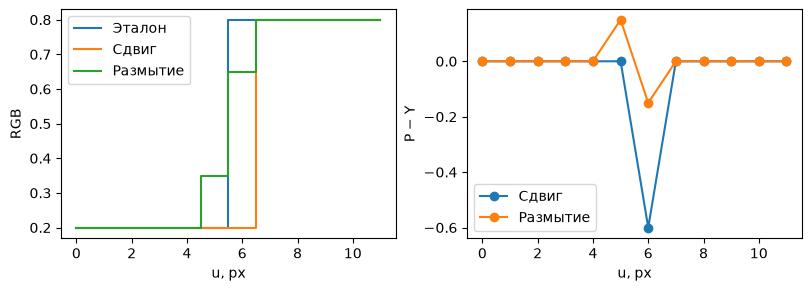

In [8]:
edge = np.r_[np.full(6,.2),np.full(6,.8)]
offset = np.r_[edge[0],edge[:-1]]
blur = np.convolve(np.pad(edge,1,mode="edge"),[.25,.5,.25],mode="valid")
fig,axes = plt.subplots(1,2,figsize=(8,2.8),layout="constrained")
labels = ["Эталон","Сдвиг","Размытие"] if lang=="ru" else ["Reference","Shift","Blur"]
for a,title in zip((edge,offset,blur),labels):
    axes[0].step(range(len(a)),a,where="mid",label=title)
for a,title in zip((offset,blur),labels[1:]):
    axes[1].plot(a-edge,"o-",label=title)
axes[0].set(xlabel="u, px",ylabel="RGB"); axes[1].set(xlabel="u, px",ylabel="P − Y")
for ax in axes: ax.legend()
plt.show()
assert np.allclose((blur-edge)[5:7],[.15,-.15])

## Сколько стоит один кадр

В учебной сцене на пятно идут 14 чисел: $3+3+4+3+1$. Если плотно записать их как float32 по 4 байта, получим $14\cdot4=56$ байт на пятно и $117\cdot56=6552$ байта на 117 пятен. Это **расчёт полезных числовых данных**. Текстовый JSON занимает больше из-за ключей, скобок и десятичных цифр. В памяти Python к словарям и спискам добавляются служебные данные. Во время обучения нужны градиенты, состояния Adam, промежуточные изображения и граф вычислений. Сферические гармоники в полной модели меняют число параметров.

Код ниже отдельно показывает размер JSON-файла и измеряет время рендера без чтения файла и без рисования графика. Сначала пробный кадр, затем медиана пяти отдельных замеров. Если один кадр занял 20 миллисекунд, в секунде 1000 миллисекунд, значит $1000/20=50$ кадров/с при последовательных вызовах. При сравнении двух рендереров им передают одну сцену, те же камеры и разрешение на одном устройстве. При выборе между двумя сценами у них может быть разное число пятен. Тогда фиксируют рендерер, траекторию и размер кадра, а число пятен каждой сцены записывают рядом с её качеством и временем. Для CUDA замер требует синхронизации или событий GPU, иначе таймер может измерить лишь постановку работы в очередь.


Ещё один замер включает tracemalloc только вокруг одного прогретого вызова. Пик — максимальное число одновременно занятых байтов, которые видит этот счётчик в Python, включая зарегистрированные библиотекой выделения. Это отдельный замер от таймера. Он не включает уже загруженную модель, память всего процесса, драйвера и видеокарты.

In [9]:
ms = benchmark(lambda: render_scene(photo_model,image["camera"],w,h),repeats=5)
print("resolution:", w,h," · CPU median ms:",round(ms,3))
print("frames/s:", round(1000/ms,2))
print("float32 payload B:", len(photo_model["splats"])*14*4, "JSON file B:", reference_path.stat().st_size)

import tracemalloc
tracemalloc.start()
try:
    rendered = render_scene(photo_model,image["camera"],w,h)
    _, peak_bytes = tracemalloc.get_traced_memory()
finally:
    tracemalloc.stop()
print("traced CPU render peak (bytes):", peak_bytes)


resolution: 80 60  · CPU median ms: 70.468
frames/s: 14.19
float32 payload B: 6552 JSON file B: 39038
traced CPU render peak (bytes): 737839


## Опыт

Вариант с большим числом пятен улучшил PSNR только в обучающих ракурсах, а время кадра выросло. Какая проверка покажет, что именно стало лучше?

<details><summary>Разбор</summary>

Сохраним обе сцены и пройдём одни и те же отложенные камеры. Рядом положим эталон, две версии рендера и карты ошибки на общей шкале. Меньшая ошибка в обучающем виде может означать более точную подгонку знакомой детали, запоминание блика или лишнее пятно за поверхностью. Сопоставление новых ракурсов показывает, пережило ли улучшение смену камеры. Время и размер измеряются отдельно при одинаковой задаче.

</details>


## На какой сцене закончился опыт

У одного кадра view-04 есть RGB-эталон, модель, поза, размер изображения и схема сравнения. На свободной дуге есть только модель с движущейся камерой. Вместе эти две проверки отвечают на разные практические вопросы: сколько ошибки видно на измеренном виде и что именно начинает вести себя странно в движении.

<details><summary>Из двух вариантов A и B какой годится для просмотра при 30 кадрах в секунду?</summary>

Пусть на одном оборудовании при одном размере экрана A тратит на рендер 22 мс, B — 38 мс. Бюджет одного кадра $1000/30\approx33{,}3$ мс. A оставляет около 11,3 мс на остальную работу, B уже вышел за бюджет примерно на 4,7 мс, даже если его PSNR выше. Медиана показывает типичный кадр. Для плавного движения важны ещё медленные кадры на той же траектории. Если B точнее воспроизводит важную деталь, следующая честная пара — две модели при одинаковом бюджете, с той же камерой, разрешением и маской, а рядом разница во времени и качестве. Уменьшение разрешения только у B поменяет сразу два условия.

</details>

Для следующей съёмки результат можно сохранить буквально: список обучающих и отложенных кадров, сцену, настройки рендера, таблицу по камерам, снимок с картой ошибки и короткую траекторию с проблемным местом. Тогда гипотеза вроде «мелкие пятна мерцают» превращается в проверяемый опыт: зафиксировать сцену и камеры, изменить только фильтр, сравнить тот же участок и то же движение. Это замыкает путь от отдельной гауссианы до оценки целой статической сцены.